# Import modules:

In [127]:
import numpy as np
import matplotlib.pyplot as plt

In [128]:
class Graph:
    def __init__(self):
        self.fig, self.ax = plt.subplots()

        # x = 0 and y = 0 axes
        self.ax.spines['left'].set_position('zero')
        self.ax.spines['bottom'].set_position('zero')
        self.ax.spines['top'].set_color('none')
        self.ax.spines['right'].set_color('none')

        # Arrowheads
        self.ax.plot(1, 0, '>k',
                     transform=self.ax.get_yaxis_transform(),
                     clip_on=False)
        self.ax.plot(0, 1, '^k',
                     transform=self.ax.get_xaxis_transform(),
                     clip_on=False)

        #self.ax.set_xlim(-5, 5)
        #self.ax.set_ylim(-5, 5)

    def show(self):
        plt.show()

# Define Euler function:

In [129]:
def euler_method(f, t0, y0, hn, nn):
    """
    Solves dy/dt = f(t, y) using Euler's method.

    Parameters:
        f  : Function defining the differential equation
        t0 : Initial time
        y0 : Initial condition
        hn  : Step size
        nn  : Number of iterations

    Returns:
        tn : Array of time values
        yn : Array of approximate solutions
    """

    tn = np.zeros(nn + 1)
    yn = np.zeros(nn + 1)

    tn[0] = t0
    yn[0] = y0

    for ii in range(nn):
        yn[ii+1] = yn[ii] + hn * f(tn[ii], yn[ii])
        tn[ii+1] = tn[ii] + hn
        
    return tn, yn

# Rapidly decaying function (Problem 4)

In [130]:
# Define the differential equation
def f_100(t, y):
    return -100*y

# Initial conditions
t0 = 0
y0 = 1

In [131]:
# Unstable case:
hn = 0.025
nn = 4
tn25, yn25 = euler_method(f_100, t0, y0, hn, nn)
print(f" For Time :{tn25}")
print(f" yy = {yn25}")

 For Time :[0.    0.025 0.05  0.075 0.1  ]
 yy = [ 1.     -1.5     2.25   -3.375   5.0625]


In [132]:
# Stable case:
hn = 0.005
nn = 20
tn05, yn05 = euler_method(f_100, t0, y0, hn, nn)
print(f" For Time :{tn05}")
print(f" yy = {yn05}")

 For Time :[0.    0.005 0.01  0.015 0.02  0.025 0.03  0.035 0.04  0.045 0.05  0.055
 0.06  0.065 0.07  0.075 0.08  0.085 0.09  0.095 0.1  ]
 yy = [1.00000000e+00 5.00000000e-01 2.50000000e-01 1.25000000e-01
 6.25000000e-02 3.12500000e-02 1.56250000e-02 7.81250000e-03
 3.90625000e-03 1.95312500e-03 9.76562500e-04 4.88281250e-04
 2.44140625e-04 1.22070312e-04 6.10351562e-05 3.05175781e-05
 1.52587891e-05 7.62939453e-06 3.81469727e-06 1.90734863e-06
 9.53674316e-07]


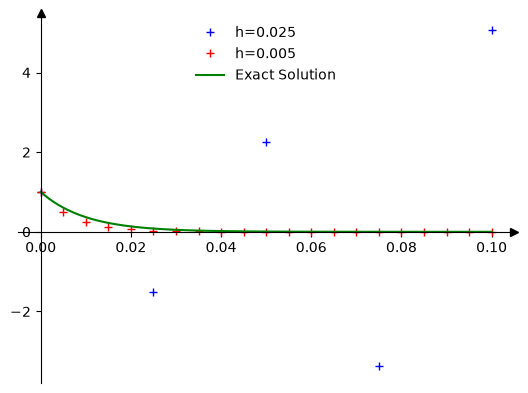

In [133]:
tt = np.arange(101) / 1000
yy = y0 * np.exp( -100 * tt )
graph_euler = Graph()
graph_euler.ax.plot(tn25, yn25, "b+", label="h=0.025")
graph_euler.ax.plot(tn05, yn05, "r+", label="h=0.005")
graph_euler.ax.plot(tt, yy, "g", label="Exact Solution")
graph_euler.ax.legend(loc='upper center', frameon=False)

In [134]:
# Sensibility test:
hn = 0.02
nn = 50
tn200, yn200 = euler_method(f_100, t0, y0, hn, nn)

hn = 0.0199
tn199, yn199 = euler_method(f_100, t0, y0, hn, nn)

hn = 0.0201
tn201, yn201 = euler_method(f_100, t0, y0, hn, nn)



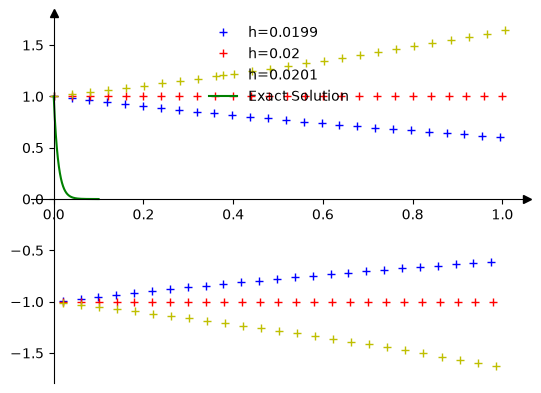

In [135]:
tt = np.arange(1001) / 10000
yy = y0 * np.exp( -100 * tt )
graph_euler_sens = Graph()
graph_euler_sens.ax.plot(tn199, yn199, "b+", label="h=0.0199")
graph_euler_sens.ax.plot(tn200, yn200, "r+", label="h=0.02")
graph_euler_sens.ax.plot(tn201, yn201, "y+", label="h=0.0201")
graph_euler_sens.ax.plot(tt, yy, "g", label="Exact Solution")
graph_euler_sens.ax.legend(loc='upper center', frameon=False)

# Define RK4 function:

In [136]:
def rk4_method(f, t0, y0, hn, nn):
    """
    Solves dy/dt = f(t, y) using RK4 method.

    Parameters:
        f  : Function defining the differential equation
        t0 : Initial time
        y0 : Initial condition
        hn  : Step size
        nn  : Number of iterations

    Returns:
        tn : Array of time values
        yn : Array of approximate solutions
    """
    # Allocate arrays
    tn = np.zeros(nn + 1)
    yn = np.zeros(nn + 1)

    # Initial conditions
    tn[0] = t0
    yn[0] = y0

    # Time integration
    for ii in range(nn):

        ti = tn[ii]
        yi = yn[ii]

        k1 = f(ti, yi)
        k2 = f(ti + hn/2, yi + hn*k1/2)
        k3 = f(ti + hn/2, yi + hn*k2/2)
        k4 = f(ti + hn, yi + hn*k3)

        yn[ii+1] = yi + hn/6 * ( k1 + 2*k2 + 2*k3 + k4 )
        tn[ii+1] = ti + hn

    return tn, yn

In [1]:
def rk4_stability(z):
    rz= 1 + z + z**2/2 + z**3/6 + z**4/24
    print(f" R({z}) = {rz}")

# Rapidly decaying function (Problem 5)

In [138]:
# Initial conditions
t0 = 0
y0 = 1

In [139]:
# Stable case:
hn = 0.025
nn = 4
tn025, yn025 = rk4_method(f_100, t0, y0, hn, nn)
print(f" For Time :{tn025}")
print(f" yy = {yn025}")
rk4_stability(-100*hn)

 For Time :[0.    0.025 0.05  0.075 0.1  ]
 yy = [1.         0.6484375  0.42047119 0.27264929 0.17679602]
 R(-2.5) = 0.6484375000000002


In [140]:
# Unstable case:
hn = 0.03
nn = 4
tn03, yn03 = rk4_method(f_100, t0, y0, hn, nn)
print(f" For Time :{tn03}")
print(f" yy = {yn03}")
rk4_stability(-100*hn)

 For Time :[0.   0.03 0.06 0.09 0.12]
 yy = [1.         1.375      1.890625   2.59960938 3.57446289]
 R(-3.0) = 1.375


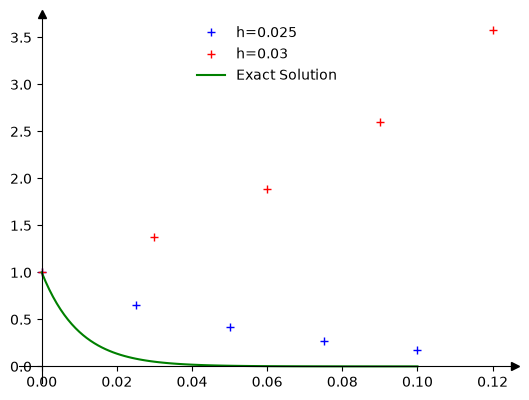

In [141]:
tt = np.arange(101) / 1000
yy = y0 * np.exp( -100 * tt )
graph_rk4 = Graph()
graph_rk4.ax.plot(tn025, yn025, "b+", label="h=0.025")
graph_rk4.ax.plot(tn03, yn03, "r+", label="h=0.03")
graph_rk4.ax.plot(tt, yy, "g", label="Exact Solution")
graph_rk4.ax.legend(loc='upper center', frameon=False)

In [142]:
hn = 0.0277
rk4_stability(-100*hn)
nn = 50
tn0277, yn0277 = rk4_method(f_100, t0, y0, hn, nn)

hn = 0.02785
rk4_stability(-100*hn)
tn02785, yn02785 = rk4_method(f_100, t0, y0, hn, nn)

hn = 0.028
rk4_stability(-100*hn)
tn028, yn028 = rk4_method(f_100, t0, y0, hn, nn)

 R(-2.77) = 0.9771859337500004
 R(-2.785) = 0.9995574896093751
 R(-2.8000000000000003) = 1.0224000000000006


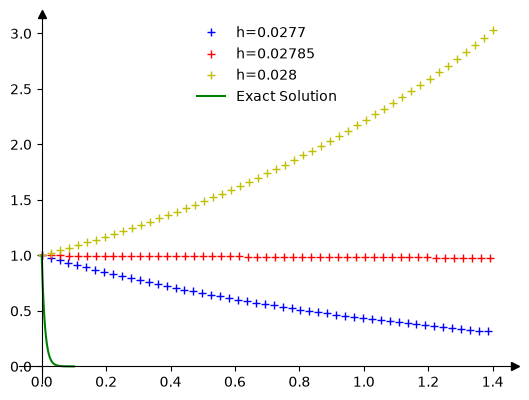

In [143]:
tt = np.arange(1001) / 10000
yy = y0 * np.exp( -100 * tt )
graph_rk4_sens = Graph()
graph_rk4_sens.ax.plot(tn0277, yn0277, "b+", label="h=0.0277")
graph_rk4_sens.ax.plot(tn02785, yn02785, "r+", label="h=0.02785")
graph_rk4_sens.ax.plot(tn028, yn028, "y+", label="h=0.028")
graph_rk4_sens.ax.plot(tt, yy, "g", label="Exact Solution")
graph_rk4_sens.ax.legend(loc='upper center', frameon=False)